# Experimental Setup
The first notebook establishes the unmodified-data baselines. This notebook repeats the same seed, stratified split, feature engineering, and training subset; five-fold average precision guides model and sampling selection.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay, RocCurveDisplay, precision_recall_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
plt.style.use('seaborn-v0_8-whitegrid')
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
ROOT = Path.cwd()
DATA_CANDIDATES = [ROOT / 'creditcard.csv', ROOT.parent / 'creditcard.csv',
                   ROOT.parent.parent / 'creditcard.csv', ROOT / 'data' / 'creditcard.csv']
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place creditcard.csv in this project root or its parent directory.')
OUT = ROOT if (ROOT / 'images').exists() else ROOT.parent
(OUT / 'images').mkdir(exist_ok=True)
(OUT / 'results').mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
X_raw, y = df.drop(columns='Class').copy(), df['Class'].astype('int8')
X_train_full, X_test_raw, y_train_full, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=SEED, stratify=y)
X_train_raw, _, y_train, _ = train_test_split(
    X_train_full, y_train_full, train_size=30_000, random_state=SEED, stratify=y_train_full)

def add_time_cycle(frame):
    features = frame.drop(columns='Time').copy()
    hour = (frame['Time'].to_numpy() % 86_400) / 86_400 * 2 * np.pi
    features['hour_sin'], features['hour_cos'] = np.sin(hour), np.cos(hour)
    return features

X_train, X_test = add_time_cycle(X_train_raw), add_time_cycle(X_test_raw)
PCA_COLUMNS = [f'V{i}' for i in range(1, 29)]
PREPROCESSOR = ColumnTransformer(
    [('amount', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                          ('scale', StandardScaler())]), ['Amount']),
     ('components', 'passthrough', PCA_COLUMNS),
     ('time_cycle', 'passthrough', ['hour_sin', 'hour_cos'])], remainder='drop')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f'Training subset: {X_train.shape}, untouched test: {X_test.shape}')
print(f'Training fraud rate: {y_train.mean():.4%}; test fraud rate: {y_test.mean():.4%}')

Training subset: (30000, 31), untouched test: (56962, 31)
Training fraud rate: 0.1733%; test fraud rate: 0.1720%


# Baseline Reference
The baseline reference is recomputed using the same estimator settings as Notebook 1. The 30,000-row training subset is stratified; the full test split remains unaltered.

In [2]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1500, random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=7, n_jobs=-1),
    'Linear SVM': LinearSVC(C=1.0, random_state=SEED, max_iter=5000),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=120, max_depth=4, learning_rate=0.08,
                            subsample=0.9, colsample_bytree=0.9, eval_metric='logloss',
                            n_jobs=-1, random_state=SEED),
}

def make_pipeline(estimator, strategy='none'):
    steps = [('preprocess', clone(PREPROCESSOR))]
    if strategy == 'under':
        steps.append(('sampler', RandomUnderSampler(random_state=SEED)))
    elif strategy == 'smote':
        steps.append(('sampler', SMOTE(random_state=SEED, k_neighbors=3)))
    steps.append(('model', estimator))
    return ImbPipeline(steps)

def scores_for(fitted, features):
    return fitted.predict_proba(features)[:, 1] if hasattr(fitted, 'predict_proba') else fitted.decision_function(features)

def evaluate(name, fitted, features=X_test, labels=y_test, threshold=None):
    scores = scores_for(fitted, features)
    predicted = fitted.predict(features) if threshold is None else (scores >= threshold).astype('int8')
    return {'model': name, 'accuracy': accuracy_score(labels, predicted),
            'precision': precision_score(labels, predicted, zero_division=0),
            'fraud_recall': recall_score(labels, predicted, zero_division=0),
            'f1': f1_score(labels, predicted, zero_division=0),
            'roc_auc': roc_auc_score(labels, scores),
            'pr_auc': average_precision_score(labels, scores),
            'threshold': threshold, 'confusion_matrix': confusion_matrix(labels, predicted),
            'scores': scores, 'predictions': predicted}

baseline_fits, baseline_rows = {}, []
for model_name, estimator in models.items():
    fitted = make_pipeline(clone(estimator))
    fitted.fit(X_train, y_train)
    baseline_fits[model_name] = fitted
    baseline_rows.append(evaluate(model_name, fitted))
baseline_results = pd.DataFrame([{k: v for k, v in row.items() if k not in {'confusion_matrix','scores','predictions'}}
                                 for row in baseline_rows])
display(baseline_results.sort_values('pr_auc', ascending=False).round(4))

,model,accuracy,precision,fraud_recall,f1,roc_auc,pr_auc,threshold
4,Random Forest,0.9994,0.8523,0.7653,0.8065,0.9470,0.8327,None
5,XGBoost,0.9994,0.8427,0.7653,0.8021,0.9740,0.8313,None
2,Linear SVM,0.9993,0.8571,0.7347,0.7912,0.9447,0.7570,None
1,KNN,0.9993,0.8132,0.7551,0.7831,0.9335,0.7378,None
0,Logistic Regression,0.9992,0.7653,0.7653,0.7653,0.9540,0.7350,None
3,Decision Tree,0.9992,0.7653,0.7653,0.7653,0.8823,0.5861,None


# Threshold Analysis
Thresholds are selected using out-of-fold predictions from the training subset only. The threshold maximizing training out-of-fold F1 is then evaluated once on the untouched test set.

In [3]:
threshold_model_name = 'Logistic Regression'
threshold_pipeline = make_pipeline(clone(models[threshold_model_name]))
threshold_oof = cross_val_predict(threshold_pipeline, X_train, y_train, cv=cv, method='predict_proba', n_jobs=1)[:, 1]
precision_values, recall_values, thresholds = precision_recall_curve(y_train, threshold_oof)
f1_values = 2 * precision_values[:-1] * recall_values[:-1] / np.maximum(precision_values[:-1] + recall_values[:-1], 1e-12)
best_index = int(np.argmax(f1_values))
selected_threshold = float(thresholds[best_index])
threshold_fit = make_pipeline(clone(models[threshold_model_name])).fit(X_train, y_train)
threshold_rows = []
for threshold in [0.5, 0.2, 0.1, 0.05, selected_threshold]:
    row = evaluate(f'{threshold_model_name} @ {threshold:.4f}', threshold_fit, threshold=threshold)
    tn, fp, fn, tp = row['confusion_matrix'].ravel()
    threshold_rows.append({'threshold': threshold, 'precision': row['precision'], 'fraud_recall': row['fraud_recall'],
                           'false_positives': fp, 'false_negatives': fn, 'f1': row['f1']})
threshold_table = pd.DataFrame(threshold_rows).drop_duplicates('threshold').sort_values('threshold', ascending=False)
print(f'Training OOF F1-selected threshold: {selected_threshold:.6f}')
display(threshold_table.round(4))
threshold_table.to_csv(OUT / 'results' / 'threshold_analysis.csv', index=False)

Training OOF F1-selected threshold: 0.177575


,threshold,precision,fraud_recall,false_positives,false_negatives,f1
0,0.5000,0.7653,0.7653,23,23,0.7653
1,0.2000,0.7500,0.7959,26,20,0.7723
4,0.1776,0.7500,0.7959,26,20,0.7723
2,0.1000,0.7290,0.7959,29,20,0.7610
3,0.0500,0.6807,0.8265,38,17,0.7465


# Random Under-Sampling
Under-sampling is applied within each cross-validation training fold. Its reduction in majority examples is intentional, but may discard useful genuine-transaction variation.

# SMOTE Oversampling
SMOTE is applied inside each training fold after preprocessing. No synthetic point is generated from validation or test observations.

# Hyperparameter Tuning
Each classifier and training strategy receives a compact grid scored by five-fold average precision. The same stratified folds and random seed are used throughout.

# Leakage-Safe Pipelines
The pipeline order is preprocessing, optional sampler, then classifier. Grid search clones and fits the entire pipeline inside each fold.

In [4]:
parameter_grids = {
    'Logistic Regression': {'model__C': [0.1, 1.0]},
    'KNN': {'model__n_neighbors': [5, 9]},
    'Linear SVM': {'model__C': [0.1, 1.0]},
    'Decision Tree': {'model__max_depth': [4, 8]},
    'Random Forest': {'model__n_estimators': [80], 'model__max_depth': [None, 8]},
    'XGBoost': {'model__n_estimators': [80], 'model__max_depth': [3, 5]},
}
strategies = {'Original': 'none', 'Under-sampled': 'under', 'SMOTE': 'smote'}
searches, tuned_rows = {}, []
for strategy_name, strategy in strategies.items():
    for model_name, estimator in models.items():
        print(f'Fitting {strategy_name} : {model_name}')
        search = GridSearchCV(make_pipeline(clone(estimator), strategy), parameter_grids[model_name],
                              scoring='average_precision', cv=cv, n_jobs=-1, refit=True,
                              return_train_score=False, error_score='raise')
        search.fit(X_train, y_train)
        key = (strategy_name, model_name)
        searches[key] = search
        row = evaluate(f'{strategy_name}: {model_name}', search.best_estimator_)
        row.update({'strategy': strategy_name, 'model_name': model_name,
                    'cv_pr_auc': search.best_score_, 'best_params': str(search.best_params_)})
        tuned_rows.append(row)

tuned_results = pd.DataFrame(tuned_rows)
display(tuned_results[['strategy','model_name','cv_pr_auc','accuracy','precision','fraud_recall','f1','roc_auc','pr_auc','best_params']]
        .sort_values('cv_pr_auc', ascending=False).round(4))

Fitting Original : Logistic Regression


Fitting Original : KNN


Fitting Original : Linear SVM


Fitting Original : Decision Tree


Fitting Original : Random Forest


...

Fitting SMOTE : Linear SVM


Fitting SMOTE : Decision Tree


Fitting SMOTE : Random Forest


Fitting SMOTE : XGBoost


,strategy,model_name,cv_pr_auc,accuracy,precision,fraud_recall,f1,roc_auc,pr_auc,best_params
16,SMOTE,Random Forest,0.8663,0.9994,0.8352,0.7755,0.8042,0.9512,0.8208,"{'model__max_depth': None, 'model__n_estimator..."
10,Under-sampled,Random Forest,0.8526,0.9824,0.0807,0.8878,0.1480,0.9749,0.7368,"{'model__max_depth': 8, 'model__n_estimators':..."
5,Original,XGBoost,0.8516,0.9994,0.8506,0.7551,0.8000,0.9743,0.8186,"{'model__max_depth': 3, 'model__n_estimators':..."
17,SMOTE,XGBoost,0.8438,0.9983,0.5062,0.8367,0.6308,0.9733,0.7127,"{'model__max_depth': 3, 'model__n_estimators':..."
2,Original,Linear SVM,0.8415,0.9994,0.8588,0.7449,0.7978,0.9424,0.7541,{'model__C': 0.1}
0,Original,Logistic Regression,0.8307,0.9991,0.7527,0.7143,0.7330,0.9668,0.7404,{'model__C': 0.1}
4,Original,Random Forest,0.8211,0.9994,0.8506,0.7551,0.8000,0.9473,0.8296,"{'model__max_depth': None, 'model__n_estimator..."
12,SMOTE,Logistic Regression,0.7999,0.9937,0.1981,0.8673,0.3226,0.9635,0.6551,{'model__C': 0.1}
14,SMOTE,Linear SVM,0.7636,0.9936,0.1926,0.8469,0.3138,0.9582,0.6690,{'model__C': 0.1}
11,Under-sampled,XGBoost,0.7523,0.9671,0.0442,0.8776,0.0841,0.9730,0.6271,"{'model__max_depth': 3, 'model__n_estimators':..."


# Final Evaluation
The final score table uses only test predictions from models selected by training-fold average precision. The operating threshold is selected from out-of-fold training predictions, never from the test set.

In [5]:
# Choose one tuned configuration per strategy using cross-validated AP only.
selected_rows = []
for strategy_name in strategies:
    candidates = [row for row in tuned_rows if row['strategy'] == strategy_name]
    selected_rows.append(max(candidates, key=lambda row: row['cv_pr_auc']))
selected_labels = [row['model'] for row in selected_rows]
selected_fits = {row['model']: searches[(row['strategy'], row['model_name'])].best_estimator_
                 for row in selected_rows}

# Reuse OOF threshold selection for the CV-selected final model.
selected_final_label = max(selected_rows, key=lambda row: row['cv_pr_auc'])['model']
selected_strategy, selected_model = selected_final_label.split(': ', 1)
selected_pipeline = searches[(selected_strategy, selected_model)].best_estimator_
threshold_method = 'predict_proba' if hasattr(selected_pipeline, 'predict_proba') else 'decision_function'
selected_oof = cross_val_predict(make_pipeline(clone(models[selected_model]), strategies[selected_strategy]),
                                 X_train, y_train, cv=cv, method=threshold_method, n_jobs=1)
if selected_oof.ndim == 2:
    selected_oof = selected_oof[:, 1]
prec, rec, cutoffs = precision_recall_curve(y_train, selected_oof)
f1_oof = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
selected_threshold = float(cutoffs[int(np.argmax(f1_oof))])

final_rows, final_predictions, final_scores = [], {}, {}
for label, fitted in selected_fits.items():
    result = evaluate(label, fitted)
    final_rows.append({key: value for key, value in result.items() if key not in {'confusion_matrix','scores','predictions'}})
    final_predictions[label], final_scores[label] = result['predictions'], result['scores']
threshold_result = evaluate(f'{selected_final_label} @ OOF threshold', selected_pipeline, threshold=selected_threshold)
final_rows.append({key: value for key, value in threshold_result.items() if key not in {'confusion_matrix','scores','predictions'}})
final_predictions[f'{selected_final_label} @ OOF threshold'] = threshold_result['predictions']
final_scores[f'{selected_final_label} @ OOF threshold'] = threshold_result['scores']
final_results = pd.DataFrame(final_rows)
final_results.to_csv(OUT / 'results' / 'final_test_results.csv', index=False)
full_comparison = pd.DataFrame([{k:v for k,v in row.items() if k not in {'confusion_matrix','scores','predictions'}} for row in tuned_rows])
full_comparison.to_csv(OUT / 'results' / 'model_comparison.csv', index=False)
print(f'Selected configuration by CV AP: {selected_final_label}')
print(f'OOF-selected operating threshold: {selected_threshold:.6f}')
display(final_results.round(4))

Selected configuration by CV AP: SMOTE: Random Forest
OOF-selected operating threshold: 0.441333


,model,accuracy,precision,fraud_recall,f1,roc_auc,pr_auc,threshold
0,Original: XGBoost,0.9994,0.8506,0.7551,0.8000,0.9743,0.8186,NaN
1,Under-sampled: Random Forest,0.9824,0.0806,0.8878,0.1478,0.9749,0.7368,NaN
2,SMOTE: Random Forest,0.9994,0.8352,0.7755,0.8042,0.9512,0.8210,NaN
3,SMOTE: Random Forest @ OOF threshold,0.9994,0.8316,0.8061,0.8187,0.9512,0.8210,0.4413


# Comparison Visualizations
The plots below compare test-set predictions from each strategy's CV-selected model. Confusion matrices are shown at the default 0.5 threshold, except the separately labeled OOF-threshold result.

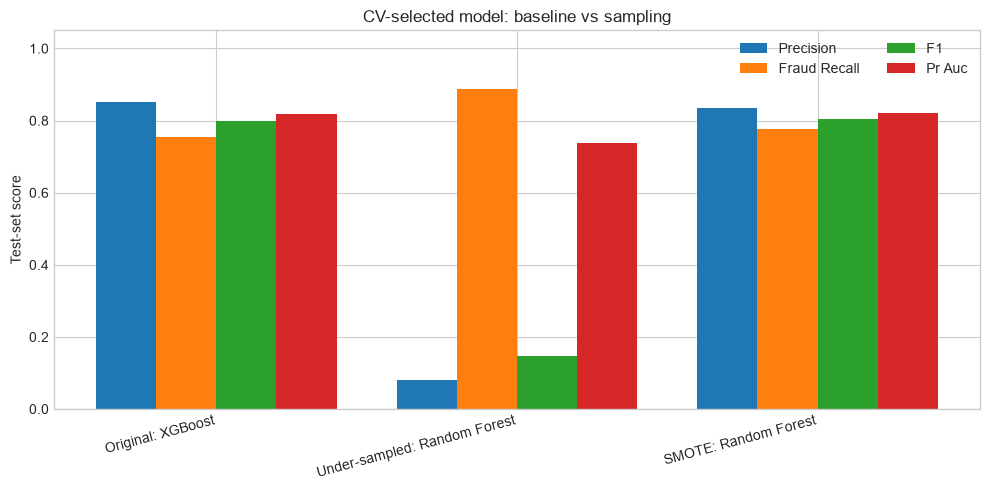

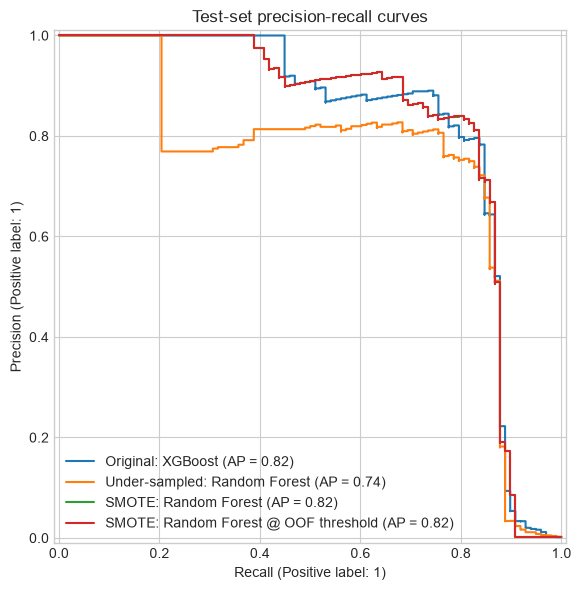

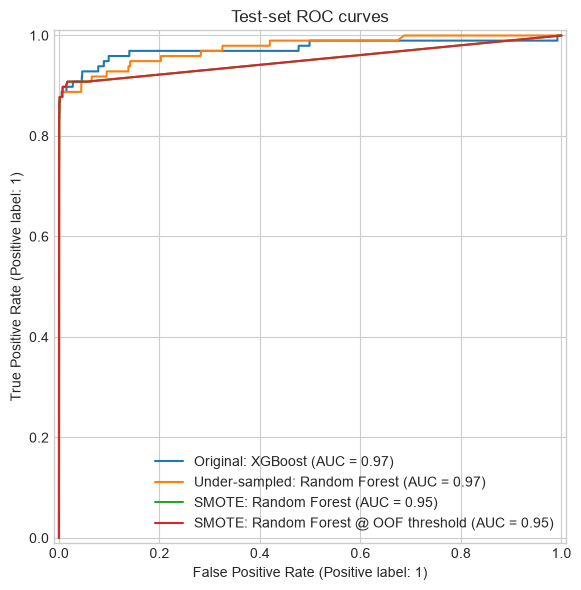

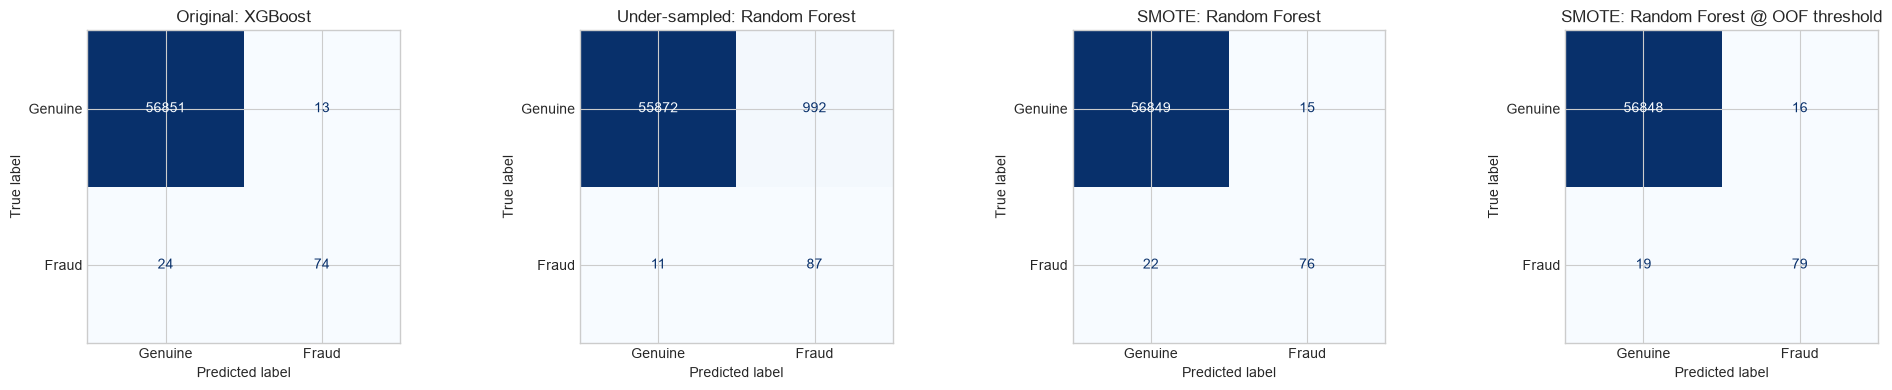

In [6]:
selected_default = final_results.iloc[:3].copy()
fig, axis = plt.subplots(figsize=(10, 5))
positions = np.arange(len(selected_default))
width = 0.2
for offset, metric in enumerate(['precision','fraud_recall','f1','pr_auc']):
    axis.bar(positions + (offset - 1.5) * width, selected_default[metric], width, label=metric.replace('_',' ').title())
axis.set_xticks(positions, selected_default['model'], rotation=15, ha='right')
axis.set_ylim(0, 1.05)
axis.set_ylabel('Test-set score')
axis.set_title('CV-selected model: baseline vs sampling')
axis.legend(ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(OUT / 'images' / 'baseline_vs_resampling.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axis = plt.subplots(figsize=(7, 6))
for label, scores in final_scores.items():
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=label, ax=axis)
axis.set_title('Test-set precision-recall curves')
fig.tight_layout()
fig.savefig(OUT / 'images' / 'precision_recall_curve.png', dpi=180, bbox_inches='tight')
plt.show()
fig, axis = plt.subplots(figsize=(7, 6))
for label, scores in final_scores.items():
    RocCurveDisplay.from_predictions(y_test, scores, name=label, ax=axis)
axis.set_title('Test-set ROC curves')
fig.tight_layout()
fig.savefig(OUT / 'images' / 'roc_curves.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, len(final_predictions), figsize=(5 * len(final_predictions), 4))
axes = np.atleast_1d(axes)
for axis, (label, predicted) in zip(axes, final_predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, predicted), display_labels=['Genuine','Fraud']).plot(
        ax=axis, cmap='Blues', colorbar=False, values_format='d')
    axis.set_title(label)
fig.tight_layout()
fig.savefig(OUT / 'images' / 'final_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

# Results and Discussion
Compare precision and fraud recall alongside PR-AUC, not accuracy alone. Under-sampling can improve minority exposure but discards majority examples; SMOTE retains majority coverage while synthesizing minority points. The selected strategy is the one with the highest mean five-fold average precision, and its precision-recall trade-off should be judged against operational false-alarm capacity.

In [7]:
best_by_strategy = tuned_results.loc[tuned_results.groupby('strategy')['cv_pr_auc'].idxmax()]
display(best_by_strategy[['strategy','model_name','cv_pr_auc','precision','fraud_recall','f1','roc_auc','pr_auc']]
        .sort_values('cv_pr_auc', ascending=False).round(4))
print('Final test false negatives : false positives:')
for label, predicted in final_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, predicted).ravel()
    print(f'{label}: FN={fn:,}, FP={fp:,}, TP={tp:,}, TN={tn:,}')

,strategy,model_name,cv_pr_auc,precision,fraud_recall,f1,roc_auc,pr_auc
16,SMOTE,Random Forest,0.8663,0.8352,0.7755,0.8042,0.9512,0.8208
10,Under-sampled,Random Forest,0.8526,0.0807,0.8878,0.1480,0.9749,0.7368
5,Original,XGBoost,0.8516,0.8506,0.7551,0.8000,0.9743,0.8186


Final test false negatives : false positives:
Original: XGBoost: FN=24, FP=13, TP=74, TN=56,851
Under-sampled: Random Forest: FN=11, FP=992, TP=87, TN=55,872
SMOTE: Random Forest: FN=22, FP=15, TP=76, TN=56,849
SMOTE: Random Forest @ OOF threshold: FN=19, FP=16, TP=79, TN=56,848
